In [2]:
from pathlib import Path

# Get the project root directory
PROJECT_ROOT = Path.cwd().parent

# Define dataset paths
WHITEBOARD_PATH = PROJECT_ROOT / "datasets" / "whiteboard"
HANDWRITING_PATH = PROJECT_ROOT / "datasets" / "handwriting"

print("Project Root:", PROJECT_ROOT)
print("Whiteboard Path:", WHITEBOARD_PATH)
print("Handwriting Path:", HANDWRITING_PATH)

# Check whether folders exist
print("\nWhiteboard exists:", WHITEBOARD_PATH.exists())
print("Handwriting exists:", HANDWRITING_PATH.exists())

Project Root: c:\Users\rohit\OneDrive\Desktop\BoardMindAI
Whiteboard Path: c:\Users\rohit\OneDrive\Desktop\BoardMindAI\datasets\whiteboard
Handwriting Path: c:\Users\rohit\OneDrive\Desktop\BoardMindAI\datasets\handwriting

Whiteboard exists: True
Handwriting exists: True


In [3]:
import cv2
import matplotlib.pyplot as plt

train_images = WHITEBOARD_PATH / "train" / "images"
train_labels = WHITEBOARD_PATH / "train" / "labels"

image_files = list(train_images.glob("*"))

print("Total training images:", len(image_files))

image_path = image_files[0]

label_path = train_labels / f"{image_path.stem}.txt"

print("\nImage:", image_path.name)
print("Annotation:", label_path.name)

if label_path.exists():
    print("\nYOLO Annotation:")
    print(label_path.read_text())
else:
    print("Annotation file not found!")

Total training images: 1608

Image: 1-100-_jpg.rf.8631f615f0292d6177633f1b64e2ee93.jpg
Annotation: 1-100-_jpg.rf.8631f615f0292d6177633f1b64e2ee93.txt

YOLO Annotation:
0 0.9273732046875001 1 0.8413628875000001 0.061059334374999996 0.12061819843749999 0.026518165625 0 0.7362507640625 0 0.9714330234374999 0.3313637453125 1 0.9273732046875001 1


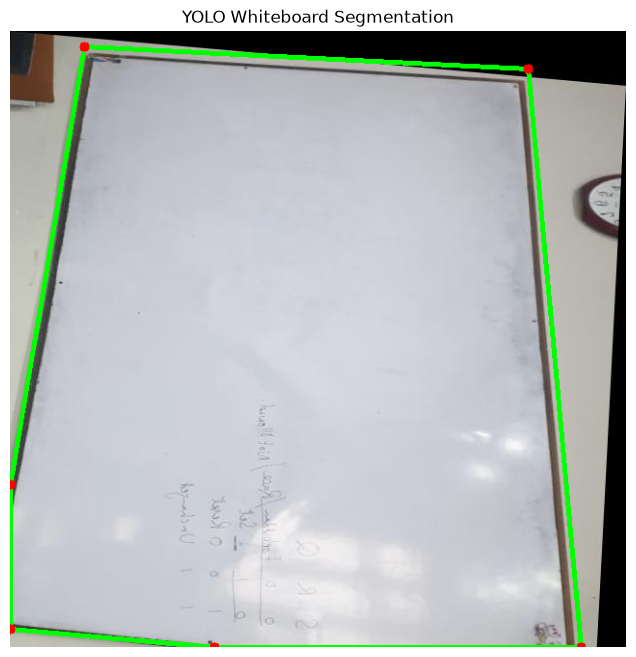

In [6]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Select image
image_path = image_files[0]
label_path = train_labels / f"{image_path.stem}.txt"

# Read image
image = cv2.imread(str(image_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

height, width = image.shape[:2]

# Read segmentation annotation
annotations = label_path.read_text().strip().splitlines()

for annotation in annotations:

    values = list(map(float, annotation.split()))

    class_id = int(values[0])

    # Remaining values are polygon coordinates
    coordinates = np.array(values[1:]).reshape(-1, 2)

    # Convert normalized coordinates into pixels
    coordinates[:, 0] *= width
    coordinates[:, 1] *= height

    polygon = coordinates.astype(np.int32)

    # Draw polygon
    cv2.polylines(
        image,
        [polygon],
        isClosed=True,
        color=(0, 255, 0),
        thickness=3
    )

    # Draw polygon points
    for point in polygon:
        cv2.circle(
            image,
            tuple(point),
            5,
            (255, 0, 0),
            -1
        )

plt.figure(figsize=(12, 8))
plt.imshow(image)
plt.axis("off")
plt.title("YOLO Whiteboard Segmentation")
plt.show()


In [5]:

# Inspect the selected image and its annotation

print("IMAGE NAME:", image_path.name)
print("LABEL NAME:", label_path.name)

print("\nIMAGE DIMENSIONS:")
print("Width:", width)
print("Height:", height)

print("\nRAW YOLO ANNOTATION:")
print(label_path.read_text())

print("\nPARSED COORDINATES:")

for line in label_path.read_text().strip().splitlines():
    values = list(map(float, line.split()))

    print("Class ID:", values[0])
    print("X Center:", values[1])
    print("Y Center:", values[2])
    print("Width:", values[3])
    print("Height:", values[4])



IMAGE NAME: 1-100-_jpg.rf.8631f615f0292d6177633f1b64e2ee93.jpg
LABEL NAME: 1-100-_jpg.rf.8631f615f0292d6177633f1b64e2ee93.txt

IMAGE DIMENSIONS:
Width: 640
Height: 640

RAW YOLO ANNOTATION:
0 0.9273732046875001 1 0.8413628875000001 0.061059334374999996 0.12061819843749999 0.026518165625 0 0.7362507640625 0 0.9714330234374999 0.3313637453125 1 0.9273732046875001 1

PARSED COORDINATES:
Class ID: 0.0
X Center: 0.9273732046875001
Y Center: 1.0
Width: 0.8413628875000001
Height: 0.061059334374999996
